In [1]:
import numpy as np
import matplotlib.pyplot as plt
from importlib import resources
import pymatreader as pmr

# =========================================================================
# 1. INITIALIZATION: LOAD REFERENCE MACHINE ONCE (GLOBAL CONTEXT)
# =========================================================================
def load_machine_data(file_path=resources.files("pyRadPlan.data.machines").joinpath("protons_Generic.mat")):
    """Loads the binary machine lookup tables once into RAM memory."""
    mat_dict = pmr.read_mat(file_path)
    machine_root = mat_dict['machine'] if 'machine' in mat_dict else mat_dict
    return machine_root['data']

# Load the data block globally before running loops
GLOBAL_DATA_BLOCK = load_machine_data()


# =========================================================================
# 2. OPTIMIZED PIPELINE COMPUTATION BLOCKS
# =========================================================================
def convert_hu_to_rsp(hu_block):
    """Maps clinical HU structures to Relative Stopping Power vectors."""
    exact_hu_nodes  = [-1000.0, -950.0, -120.0,   0.0,   100.0,   200.0,  1000.0,  2000.0,  3000.0]
    exact_rsp_nodes = [   0.00,   0.05,   0.88,  1.00,    1.05,    1.10,    1.47,    1.83,    2.17]
    return np.interp(hu_block, exact_hu_nodes, exact_rsp_nodes)

def convert_ct_to_wepl(hu_block, voxel_size_mm=1.0):
    """Generates the absolute cumulative WEPL depth matrix down Axis 0."""
    rsp_grid = convert_hu_to_rsp(hu_block)
    wepl_grid = np.cumsum(rsp_grid * voxel_size_mm, axis=0)
    return wepl_grid, rsp_grid


def look_up_repository_ddd(wepl_grid, energy_mev, data_block=GLOBAL_DATA_BLOCK):
    """
    Task 1: Longitudinal Depth Dose Distribution (DDD) Grid Calculation.
    Optimized to read directly from pre-loaded memory structures.
    """
    if isinstance(wepl_grid, tuple):
        wepl_grid = wepl_grid[0]
        
    # Match the user target energy to the available database channels
    available_energies = np.array(data_block['energy'])
    energy_idx = np.argmin(np.abs(available_energies - energy_mev))
    
    # Extract data parameters directly from memory references
    ref_depths = np.array(data_block['depths'][energy_idx])      
    target_dose_curve = np.array(data_block['Z'][energy_idx])   
    
    # Vectorized 1D interpolation
    flat_wepl = wepl_grid.flatten()
    flat_ddd_dose = np.interp(flat_wepl, ref_depths, target_dose_curve, left=0.0, right=0.0)
    
    return flat_ddd_dose.reshape(wepl_grid.shape)


def apply_lateral_spreading(wepl_grid, task1_dose, energy_mev, cy=24, cz=24, data_block=GLOBAL_DATA_BLOCK):
    """
    Task 2: Lateral Gaussian Beam Spreading.
    Optimized with pre-loaded arrays and adjustable beam centers (cy, cz).
    """
    if isinstance(wepl_grid, tuple):
        wepl_grid = wepl_grid[0]
        
    # Query energy index from pre-loaded array
    available_energies = np.array(data_block['energy'])
    energy_idx = np.argmin(np.abs(available_energies - energy_mev))
    
    # Extract reference vectors
    ref_depths = np.array(data_block['depths'][energy_idx]) 
    ref_sigmas = np.array(data_block['sigma'][energy_idx])  
    
    # Extract initial entry focus configurations
    target_focus = data_block['initFocus'][energy_idx]
    fwhm_at_iso = target_focus['SisFWHMAtIso']
    author_sigma_init = fwhm_at_iso / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    
    # Interpolate physics scattering sigma vectors
    flat_wepl = wepl_grid.flatten()
    flat_sigmas = np.interp(flat_wepl, ref_depths, ref_sigmas, left=ref_sigmas[0], right=ref_sigmas[-1])
    sigma_scatter_grid = flat_sigmas.reshape(wepl_grid.shape)
    
    # Combine parameters in quadrature
    sigma_total_grid = np.sqrt(sigma_scatter_grid**2 + author_sigma_init**2)
    
    # Generate 2D cross-section coordinate grid centered around the requested beam axis
    nx, ny, nz = wepl_grid.shape
    y_indices = np.arange(ny)
    z_indices = np.arange(nz)
    Y, Z = np.meshgrid(y_indices, z_indices, indexing='ij')
    
    # Computed distance using customized entrance coordinates
    r_squared = (Y - cy)**2 + (Z - cz)**2
    r_squared_3d = r_squared[np.newaxis, :, :]
    
    # Process the analytical 2D Gaussian profiles
    gaussian_stencil = np.exp(-0.5 * r_squared_3d / (sigma_total_grid**2)) / (2.0 * np.pi * (sigma_total_grid**2))
    final_3d_dose = task1_dose * gaussian_stencil
    
    return final_3d_dose


In [2]:
# 3. SET UP INTENDED USER PHANTOM ENVIRONMENT (300 x 48 x 48)
shape = (300, 48, 48)
Energy_this = 150 

# Baseline defined entirely as uniform muscle/water tissue (0 HU)
ct_hu_phantom = np.zeros(shape, dtype=float)

# Impose an air gap entrance (-1000 HU) at the beginning of the ray field
ct_hu_phantom[0:15, :, :] = -1000.0

# Position a dense cortical bone mass block (1500 HU) inside the track
ct_hu_phantom[120:200, 24:, 15:] = 1500.0


# 4. PROCESS THROUGH THE PIPELINE
voxel_thickness = 1.0  # 1 mm step resolution
wepl_matrix = convert_ct_to_wepl(ct_hu_phantom, voxel_size_mm=1.0)
task1_dose_grid = look_up_repository_ddd(wepl_matrix, energy_mev=Energy_this)
final_physical_dose = apply_lateral_spreading(wepl_matrix, task1_dose_grid, energy_mev=Energy_this)



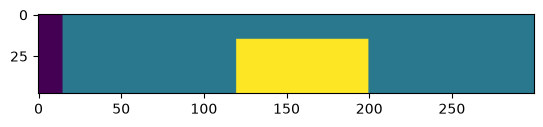

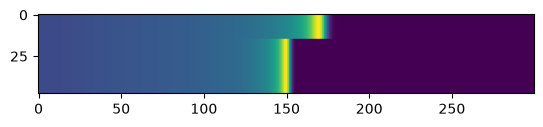

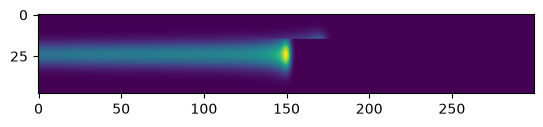

In [3]:
plt.figure()
plt.imshow(ct_hu_phantom[:,24,:].T)
plt.figure()
plt.imshow(task1_dose_grid[:,24,:].T)
plt.figure()
plt.imshow(final_physical_dose[:,24,:].T)

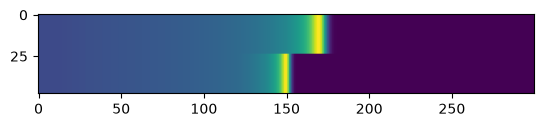

In [9]:
plt.imshow(task1_dose_grid[:,:,24].T)

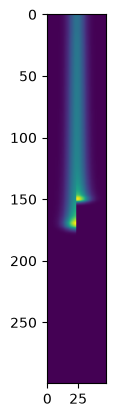

In [61]:
plt.imshow(final_physical_dose[:,:,24])

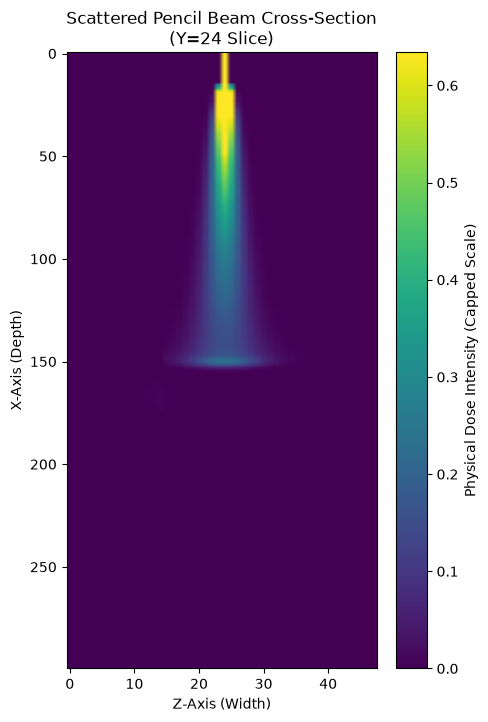

In [54]:
import matplotlib.pyplot as plt

# Extract the slice you were looking at
dose_slice = final_physical_dose[:, 24, :]

# Use a logarithmic norm or clip the maximum to see the deeper scattered beam structure
plt.figure(figsize=(5, 8))
plt.imshow(dose_slice, cmap='viridis', aspect='auto', vmax=np.percentile(dose_slice, 99.5))
plt.colorbar(label='Physical Dose Intensity (Capped Scale)')
plt.title("Scattered Pencil Beam Cross-Section\n(Y=24 Slice)")
plt.xlabel("Z-Axis (Width)")
plt.ylabel("X-Axis (Depth)")
plt.show()


In [42]:
# 3. SET UP INTENDED USER PHANTOM ENVIRONMENT (300 x 48 x 48)
shape = (300, 48, 48)

# Baseline defined entirely as uniform muscle/water tissue (0 HU)
ct_hu_phantom = np.zeros(shape, dtype=float)

# Impose an air gap entrance (-1000 HU) at the beginning of the ray field
ct_hu_phantom[0:15, :, :] = -1000.0

# Position a dense cortical bone mass block (1500 HU) inside the track
ct_hu_phantom[120:200, 24:, 15:] = 1500.0


# 4. PROCESS THROUGH THE PIPELINE
voxel_thickness = 1.0  # 1 mm step resolution

wepl_matrix = convert_ct_to_wepl(ct_hu_phantom, voxel_size_mm=1.0)
task1_dose_grid = look_up_repository_ddd(wepl_matrix, energy_mev=150.0)


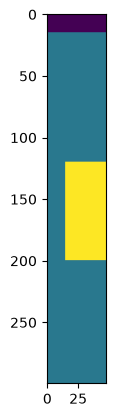

In [41]:
plt.imshow(ct_hu_phantom[:,24,:])

In [53]:
import numpy as np
import pymatreader as pmr
from importlib import resources

file_path = resources.files("pyRadPlan.data.machines").joinpath("protons_Generic.mat")
mat_dict = pmr.read_mat(file_path)
data_block = mat_dict['machine']['data'] if 'machine' in mat_dict else mat_dict['data']

available_energies = np.array(data_block['energy'])
energy_idx = np.argmin(np.abs(available_energies - 150.0))

print("Initial Sigma (at surface):", data_block['sigma'][energy_idx][0])
print("Max Sigma (at deep track):", data_block['sigma'][energy_idx][-1])


Initial Sigma (at surface): 0.0
Max Sigma (at deep track): 4.73352574799827


In [56]:
import pymatreader as pmr
from importlib import resources

file_path = resources.files("pyRadPlan.data.machines").joinpath("protons_Generic.mat")
mat_dict = pmr.read_mat(file_path)
data_block = mat_dict['machine']['data'] if 'machine' in mat_dict else mat_dict['data']

print("initFocus type:", type(data_block['initFocus']))
print("initFocus list length:", len(data_block['initFocus']))
if len(data_block['initFocus']) > 0:
    print("First item type:", type(data_block['initFocus'][0]))
    if isinstance(data_block['initFocus'][0], dict):
        print("First item keys:", data_block['initFocus'][0].keys())


initFocus type: <class 'list'>
initFocus list length: 114
First item type: <class 'dict'>
First item keys: dict_keys(['dist', 'sigma', 'SisFWHMAtIso', 'emittance'])
